# Лабораторная работа № 7 — вариант 3

Основной эксперимент — локальный HTML + API. Внешние измерения 27 октября и другие доказательства сохранены отдельно в метаданных этого блокнота (`lab7_evidence`). Выполнение блокнота не отправляет HTTP-запросы.

In [1]:
from pathlib import Path
import json, statistics
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from datetime import datetime
from IPython.display import display
ROOT = Path.cwd()
reports = {k: json.loads((ROOT / "reports" / f"run_report_{k}.json").read_text(encoding="utf8")) for k in "ABC"}
logs = {k: [json.loads(line) for line in (ROOT / "logs" / ("run_" + reports[k]["run_id"] + ".jsonl")).read_text(encoding="utf8").splitlines()] for k in "ABC"}

## Локальный стенд A/B/C

Три HTML и три API запроса в каждом режиме; все результаты содержат 165 одинаковых записей. Предварительное заполнение кэша в измерения не включено. Режим C объединяет ETag/304, gzip и водяной знак. Трафик означает байты тела до распаковки.

In [2]:
cols=["requests","statuses","accepted","rejected","error_fraction","retries","p50_ms","p95_ms","wire_body_bytes","responses_304","breaker_activations","duration_seconds","alerts","status"]
display(pd.DataFrame(reports).T[cols])
assert reports["A"]["records"] == reports["B"]["records"] == reports["C"]["records"]
assert len(reports["C"]["records"]) == 165
for k in "ABC":
    ev=[e for e in logs[k] if e["event"] == "request"]
    assert len(ev)==reports[k]["requests"]
    assert sum(e["bytes"] for e in ev)==reports[k]["wire_body_bytes"]
    assert dict(Counter(str(e["status"]) for e in ev))==reports[k]["statuses"]
print("Все три отчёта согласованы с первичными журналами.")

,requests,statuses,accepted,rejected,error_fraction,retries,p50_ms,p95_ms,wire_body_bytes,responses_304,breaker_activations,duration_seconds,alerts,status
A,6,{'200': 6},165,0,0.0,0,336.5,359.0,23411,0,0,2.047,[],green
B,6,{'200': 6},165,0,0.0,0,398.5,484.0,23411,0,0,9.5,[],green
C,6,"{'304': 3, '200': 3}",165,0,0.0,0,367.0,390.0,343,3,0,10.046,[],green


Все три отчёта согласованы с первичными журналами.


## Латентность и коды ответов

Латентность измерена по HTTP-попыткам, без ожидания допуска лимитера. Времена отдельных процессов и локального стенда не являются измерениями удалённых сайтов.

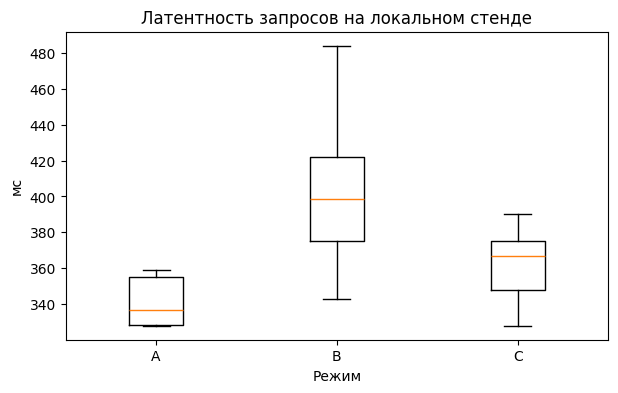

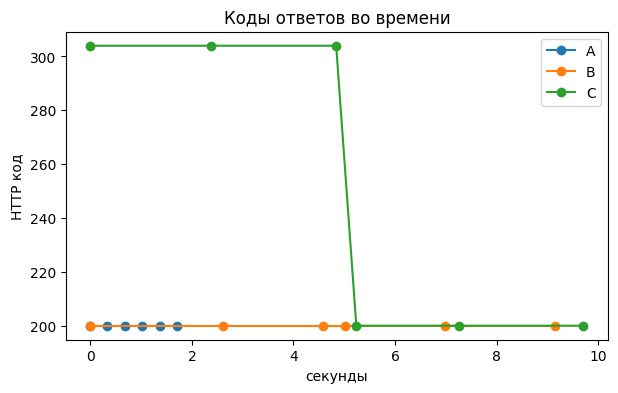

In [3]:
fig, ax = plt.subplots(figsize=(7,4))
ax.boxplot([[e["ms"] for e in logs[k] if e["event"]=="request"] for k in "ABC"])
ax.set_xticks([1, 2, 3], list("ABC"))
ax.set(xlabel="Режим", ylabel="мс", title="Латентность запросов на локальном стенде")
plt.show()
fig, ax = plt.subplots(figsize=(7,4))
for k in "ABC":
    ev=[e for e in logs[k] if e["event"]=="request"]
    t0=datetime.fromisoformat(ev[0]["ts"])
    ax.plot([(datetime.fromisoformat(e["ts"])-t0).total_seconds() for e in ev], [e["status"] for e in ev], marker="o", label=k)
ax.set(xlabel="секунды", ylabel="HTTP код", title="Коды ответов во времени")
ax.legend(); plt.show()

## История, инциденты и внешние замеры

Метаданные содержат исходные отчёты удалённых источников, robots.txt, результаты тестового стенда и исходные наборы. Разные профили истории не смешиваются. Для сравнения размера ответов 304 используется сохранённый размер содержимого; отдельный профиль incremental не сопоставляется с full.

In [4]:
import nbformat
notebook = nbformat.read(ROOT / "analysis.ipynb", as_version=4)
evidence = notebook.metadata["lab7_evidence"]
remote = {k: evidence["reports"][f"run_report_{k}.json"] for k in "ABC"}
display(pd.DataFrame(remote).T[["requests","statuses","accepted","wire_body_bytes","duration_seconds"]])
display(evidence["reports"]["fixture_isolation.json"])
print("Внешний A был после B и C; инкрементальность на внешнем источнике не заявляется.")

,requests,statuses,accepted,wire_body_bytes,duration_seconds
A,6,{'200': 6},63,154303,9.828
B,6,{'200': 6},63,154303,38.937
C,6,"{'200': 3, '304': 3}",63,939,29.453


{'404_calls': 1,
 'accepted': 2,
 'alerts': ['errors>10%', 'breaker>0'],
 'breaker_activations': 1,
 'duration_seconds': 8.312,
 'error_fraction': 0.6,
 'failure_calls': 2,
 'mean_body_bytes': 68.6,
 'mean_entity_bytes': 164.0,
 'p50_ms': 344.0,
 'p95_ms': 422.0,
 'profile': 'fixture_isolation_v1',
 'rate_429_403': 0.0,
 'rejected': 0,
 'representation_bytes': None,
 'requests': 5,
 'responses_304': 0,
 'retries': 1,
 'run_id': 'fixture_isolation_d07cb6f5964f',
 'status': 'red',
 'statuses': {'200': 2, '404': 1, '500': 2},
 'transitions': [['closed', 'open'],
  ['open', 'half-open'],
  ['half-open', 'closed']],
 'wire_body_bytes': 343}

Внешний A был после B и C; инкрементальность на внешнем источнике не заявляется.


Таблицы экономии по трём механизмам, границы внешних данных и локальных испытаний: [comparison.md](reports/comparison.md).